In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import math

In [2]:
df = pd.read_csv("poisson_sim.csv")

In [3]:
# Collect predictors and variables to predict
data = pd.get_dummies(df["prog"])
data["math"] = df["math"]
data["num_awards"] = df["num_awards"]

In [4]:
data

,1,2,3,math,num_awards
0,False,False,True,41,0
1,True,False,False,41,0
2,False,False,True,44,0
3,False,False,True,42,0
4,False,False,True,40,0
...,...,...,...,...,...
195,False,True,False,71,2
196,False,False,True,75,2
197,False,True,False,71,1
198,False,True,False,72,0


In [ ]:
def poisson_log_likelihood(y, mu):
    return y * np.log(mu) - mu - np.log(math.factorial(y))

def log_likelihood(args):
    alpha_1, alpha_2, alpha_3, beta = args
    alphas = [alpha_1, alpha_2, alpha_3]
    total = 0
    for idx, row in df.iterrows():
        y_i = row["num_awards"]
        X_i = row["math"]
        prog = int(row["prog"])

        mu = np.exp(alphas[prog - 1] + beta * X_i)

        total += poisson_log_likelihood(y_i, mu)
        
    return -total

In [11]:
initial_params = [0.0, 0.0, 0.0, 0.0]

# Minimize the negative log likelihood
result = minimize(log_likelihood, initial_params, method='L-BFGS-B')
optimal_params = result.x

In [12]:
optimal_params

array([-5.24711309, -4.16325221, -4.8773042 ,  0.07015218])

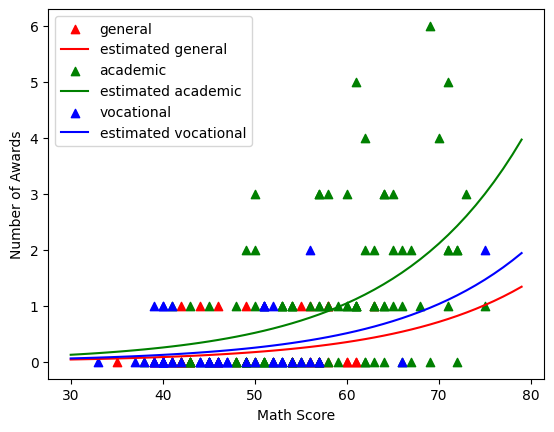

In [13]:
colors = ["red", "green", "blue"]
labels = ["general", "academic", "vocational"]

for i in range(0,3):
    beta = optimal_params[3]
    alpha_i = optimal_params[i]
    to_plot = data[data[i + 1] == 1]
    plt.scatter(to_plot["math"], to_plot["num_awards"], marker='^',color = colors[i], label = labels[i])
    plt.plot(np.arange(30,80), np.exp(alpha_i + beta * np.arange(30,80)),color = colors[i], label = f"estimated {labels[i]}")
plt.xlabel("Math Score")
plt.ylabel("Number of Awards")
plt.legend()
plt.show()